# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Luthfiana Syakira Eka Ramadani
- **Email:** ds284b6x0925@student.devacademy.id
- **ID Dicoding:** DS284B6X0925

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perkembangan jumlah pesanan dan total nilai penjualan produk setiap bulan selama periode transaksi yang tersedia, serta bulan mana yang mencatat performa tertinggi?
- **Pertanyaan 2:** Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary selama periode pengamatan, serta segmen pelanggan mana yang perlu diprioritaskan dalam strategi retensi?
- **Pertanyaan 3:** Bagaimana persebaran pelanggan berdasarkan negara bagian di Brazil, dan wilayah mana yang memberikan kontribusi jumlah pesanan serta nilai penjualan terbesar selama periode pengamatan?

## Import Semua Packages/Library yang Digunakan

In [22]:
#pengolahan data
import pandas as pd
import numpy as np
from pathlib import Path
import zipfile
import warnings

#visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

#pengaturan tampilan
pd.set_option('display.max.columns', None)
pd.set_option('display.max.rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')

## Data Wrangling

### Gathering Data

#### Load df dataset

In [23]:
#lokasi folder proyek
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

zip_candidates = list(Path(".").glob("*.zip"))
expected_csv = DATA_DIR / "E-Commerce Public Dataset" / "orders_dataset.csv"

if not expected_csv.exists() and zip_candidates:
    zip_path = zip_candidates[0]
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print(f"Dataset diekstrak dari: {zip_path}")

#cari folder yang berisi file orders_dataset.csv
orders_paths = list(DATA_DIR.rglob("orders_dataset.csv"))
if not orders_paths:
    raise FileNotFoundError(
        "File orders_dataset.csv tidak ditemukan. Pastikan File sudah diunggah "
        "atau sembilan file CSV sudah diekstrak ke dalam folder data/."
    )
CSV_DIR = orders_paths[0].parent

#nama file dan variabel DataFrame
file_names = {
    "customers": "customers_dataset.csv",
    "geolocation": "geolocation_dataset.csv",
    "order_items": "order_items_dataset.csv",
    "order_payments": "order_payments_dataset.csv",
    "order_reviews": "order_reviews_dataset.csv",
    "orders": "orders_dataset.csv",
    "product_category_translation": "product_category_name_translation.csv",
    "products": "products_dataset.csv",
    "sellers": "sellers_dataset.csv"
}

#memuat seluruh tabel CSV
for table_name, file_name in file_names.items():
    file_path = CSV_DIR / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {file_path}")
    globals()[f"{table_name}_df"] = pd.read_csv(file_path)
    print(f"{table_name}_df: {globals()[f'{table_name}_df'].shape[0]:,} baris x {globals()[f'{table_name}_df'].shape[1]} kolom")

#ringkasan ukuran seluruh tabel
dataset_summary = pd.DataFrame([
    {"table": name, "rows": globals()[f"{name}_df"].shape[0], "columns": globals()[f"{name}_df"].shape[1]}
    for name in file_names
])
display(dataset_summary)

#tampilkan contoh data dari tabel utama
display(orders_df.head())
display(order_items_df.head())
display(customers_df.head())

customers_df: 99,441 baris x 5 kolom
geolocation_df: 1,000,163 baris x 5 kolom
order_items_df: 112,650 baris x 7 kolom
order_payments_df: 103,886 baris x 5 kolom
order_reviews_df: 99,224 baris x 7 kolom
orders_df: 99,441 baris x 8 kolom
product_category_translation_df: 71 baris x 2 kolom
products_df: 32,951 baris x 9 kolom
sellers_df: 3,095 baris x 4 kolom


,table,rows,columns
0,customers,99441,5
1,geolocation,1000163,5
2,order_items,112650,7
3,order_payments,103886,5
4,order_reviews,99224,7
5,orders,99441,8
6,product_category_translation,71,2
7,products,32951,9
8,sellers,3095,4


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:** (Opsional)
- Berhasil memuat sembilan dataset yang terdiri dari data pelanggan, geolokasi, pesanan, detail prodouk, pembayaran, ulasan, produk, penjual, dan terjemahan kategori produk
- Dataset geolocation memiliki jumlah data terbesar, yaitu 1.000.163 baris, sedangkan product category translation memiliki jumlah data paling sedikit, yaitu 71 baris.
- Tabel orders dan customers masing- masing memiliki 99.441 baris.
- Tabel orders_items memiliki 112.650 baris, sedangkan order_payments memiliki 103.886 baris. Hal ini menunjukkan bahwa jumlah detail produk dan catatan pembayaran tidak selalu sama dengan jumlah pesanan.

### Assessing Data

#### Identifying data problem
Pada tahap ini dilakukan pemeriksaan kualitas data terhadap seluruh dataset untuk mengidentifikasi permasalahan yang dapat memengaruhi proses analisis. Pemeriksaan meliputi:


*   Missing value
*   Duplicate data
* Duplicate keys
* Data types
* Data validity



In [24]:
#menggabungkan seluruh dataframe ke dalam dictionary
all_data = {
    'customers': customers_df,
    'geolocation': geolocation_df,
    'order_items': order_items_df,
    'order_payments': order_payments_df,
    'order_reviews': order_reviews_df,
    'orders': orders_df,
    'product_category_translation': product_category_translation_df,
    'products': products_df,
    'sellers': sellers_df
}

#1. memeriksa missing value
missing_summary = []
for name, df in all_data.items():
    for column in df.columns:
      missing_summary.append({
          'table': name,
          'column': column,
          'missing_value': df[column].isna().sum(),
          'percentage': round(df[column].isnull().mean() * 100, 2)
      })

missing_df = pd.DataFrame(missing_summary)

missing_df = missing_df[
    missing_df['missing_value'] > 0
].sort_values('missing_value', ascending=False)

print("MISSING VALUE")
display(missing_df)

#2. memeriksa duplicate rows
duplicate_summary = []
for name, df in all_data.items():
    duplicate_summary.append({
        'table': name,
        'duplicate_rows': df.duplicated().sum(),
        'total_rows': len(df)
    })

duplicate_df = pd.DataFrame(duplicate_summary)
print("DUPLICATE ROWS")
display(duplicate_df)

#3. memeriksa duplicate keys
keys_columns = {
    'customers': ['customer_id'],
    'orders': ['order_id'],
    'order_items': ['order_id', 'order_item_id'],
    'order_payments': ['order_id', 'payment_sequential'],
    'order_reviews': ['review_id', 'order_id'],
    'products': ['product_id'],
    'sellers': ['seller_id'],
    'product_category_translation': ['product_category_name']
}

key_duplicate_summary = []
for name, columns in keys_columns.items():
  df = all_data[name]
  key_duplicate_summary.append({
      'table': name,
      'key_columns': ','.join(columns),
      'duplicate_keys': df.duplicated(subset=columns).sum()
  })

key_duplicate_df = pd.DataFrame(key_duplicate_summary)
print("DUPLICATE KEYS")
display(key_duplicate_df)

#4. memeriksa data type
for name, df in all_data.items():
  print(f"\n{name.upper()}")
  display(df.dtypes.to_frame(name='data_type'))

#5. memeriksa data validity
print("DATA VALIDITY")

print("Order Status:")
display(orders_df['order_status'].value_counts())

print('Review Score:')
display(order_reviews_df['review_score'].value_counts().sort_index())

MISSING VALUE


,table,column,missing_value,percentage
25,order_reviews,review_comment_title,87656,88.34
26,order_reviews,review_comment_message,58247,58.70
35,orders,order_delivered_customer_date,2965,2.98
34,orders,order_delivered_carrier_date,1783,1.79
40,products,product_category_name,610,1.85
42,products,product_description_lenght,610,1.85
41,products,product_name_lenght,610,1.85
43,products,product_photos_qty,610,1.85
33,orders,order_approved_at,160,0.16
44,products,product_weight_g,2,0.01


DUPLICATE ROWS


,table,duplicate_rows,total_rows
0,customers,0,99441
1,geolocation,261831,1000163
2,order_items,0,112650
3,order_payments,0,103886
4,order_reviews,0,99224
5,orders,0,99441
6,product_category_translation,0,71
7,products,0,32951
8,sellers,0,3095


DUPLICATE KEYS


,table,key_columns,duplicate_keys
0,customers,customer_id,0
1,orders,order_id,0
2,order_items,"order_id,order_item_id",0
3,order_payments,"order_id,payment_sequential",0
4,order_reviews,"review_id,order_id",0
5,products,product_id,0
6,sellers,seller_id,0
7,product_category_translation,product_category_name,0


... (18 outputs left out)

DATA VALIDITY
Order Status:


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Review Score:


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


**Steps to Take:**
- **Missing Values pada Orders:** Memeriksa nilai kosong pada kolom tanggal persetujuan dan pengiriman berdasarkan status pesanan agar tidak menghapus informasi yang masih valid.
- **Missing values pada Order Reviews:** Mempertahankan nilai kosong pada kolom komentar karena pelanggan tidak selalu memberikan komentar tertulis ketika memberikan ulasan.
- **Missing Values pada Products:** memeriksa kelengkapan atribut produk dan menangani nilai kosong sesuai kebutuhan analisis
- **Duplicate Data pada Geolocation:** Mengidentifikasi dan menghapus baris yang memiliki nilai identik pada seluruh kolom. Sementara itu, data dengan kode pos yang sama tetapi memiliki koordinat berbeda tetap dipertahankan karena dapat merepresentasikan titik lokasi yang berbeda
- **Data Types:** Mengonversi kolom tanggal menjadi tipe datetime agar dapat digunakan dalam analisis berdasarkan waktu.
- **Data Validity:** Memeriksa kesesuaian skor ulasan dan status pesanan sebelum digunakan dalam analisis.

**Insight:** (Opsional)
- Missing Values pada Order Reviews: Kolom review_comment_title memiliki 87.656 nilai kosong (88,34%), sedangkan review_comment_message memiliki 58.247 nilai kosong (58,70%).
- Missing Values pada Orders: Ditemukan nilai kosong pada kolom order_delivered_customer_date sebanyak 2.965 data, order_delivered_carrier_date sebanyak 1.783 data, dan order_approved_at sebanyak 160 data.
- Missing Values pada Products: Kolom product_category_name, product_description_lenght, product_name_lenght, dan product_photos_qty masing-masing memiliki 610 nilai kosong. Selain itu, kolom berat dan dimensi produk masing-masing memiliki 2 nilai kosong.
- Duplicate Data pada Geolocation: Ditemukan sebanyak 261.831 baris duplikat berdasarkan keseluruhan kolom.
- Duplicate Rows pada Tabel Lain: Tidak ditemukan baris duplikat pada delapan tabel lainnya.
- Duplicate Keys: Tidak ditemukan duplikasi berdasarkan kombinasi kolom kunci yang diperiksa pada tabel yang ditampilkan.
- Data Types dan Validitas: Pemeriksaan tipe data dan distribusi status pesanan serta skor ulasan dilakukan untuk memastikan kesesuaian data sebelum analisis.

### Cleaning Data

#### Fixing data problem

In [25]:
#membuat salinan seluruh data agar data asli tetap tersimpan
all_data_clean = {
    name:df.copy()
    for name, df in all_data.items()
}

#1. menghapus duplicate rows pada geolocation
geo_before = len(all_data_clean['geolocation'])

all_data_clean['geolocation']=(
    all_data_clean['geolocation']
    .drop_duplicates()
    .reset_index(drop=True)
)

geo_after =len(all_data_clean['geolocation'])
print('CLEANING GEOLOCATION')
print(f"Jumlah data sebelum cleaning: {geo_before}")
print(f"Jumlah data setelah cleaning: {geo_after}")
print(f"Jumlah duplikat yang dihapus: {geo_before - geo_after}")

#2. mengonversi kolom tanggal pada orders
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

date_conversion_summary = []

for column in date_columns:
    before_missing = all_data_clean['orders'][column].isna().sum()

    all_data_clean['orders'][column] = pd.to_datetime(
        all_data_clean['orders'][column],
        errors='coerce'
    )

    after_missing = all_data_clean['orders'][column].isna().sum()

    date_conversion_summary.append({
        'column': column,
        'data_type': str(all_data_clean['orders'][column].dtype),
        'missing_before': before_missing,
        'missing_after': after_missing,
        'new_missing': after_missing - before_missing
    })

print("\nDATE CONVERSION")
display(pd.DataFrame(date_conversion_summary))

#3. mempertahankan missing value yang masih valid
#missing values pada komentar ulasan tidak dihapus
#missing values pada atribut produk tidak diisi sembarangan
#missing values pada tanggal pesanan tetap dipertahankan

print("\n MISSING VALUES YANG DIPERTAHANKAN")

for table in ['order_reviews', 'orders', 'products']:
    df = all_data_clean[table]

    missing_count = df.isna().sum()
    missing_count = missing_count[missing_count > 0]

    print(f"\n{table.upper()}")
    display(missing_count.to_frame(name='missing_values'))

#4. memeriksa kembali hasil cleaning
print("\n HASIL AKHIR CLEANING ")

cleaning_summary = []

for name, df in all_data_clean.items():
    cleaning_summary.append({
        'table': name,
        'total_rows': len(df),
        'total_columns': len(df.columns),
        'duplicate_rows': df.duplicated().sum(),
        'missing_values': df.isna().sum().sum()
    })

cleaning_summary_df = pd.DataFrame(cleaning_summary)

display(cleaning_summary_df)

#5. memperbarui variabel dataset untuk analisis selanjutnya
customers_df = all_data_clean['customers']
geolocation_df = all_data_clean['geolocation']
order_items_df = all_data_clean['order_items']
order_payments_df = all_data_clean['order_payments']
order_reviews_df = all_data_clean['order_reviews']
orders_df = all_data_clean['orders']
product_category_translation_df = all_data_clean['product_category_translation']
products_df = all_data_clean['products']
sellers_df = all_data_clean['sellers']

CLEANING GEOLOCATION
Jumlah data sebelum cleaning: 1000163
Jumlah data setelah cleaning: 738332
Jumlah duplikat yang dihapus: 261831

DATE CONVERSION


,column,data_type,missing_before,missing_after,new_missing
0,order_purchase_timestamp,datetime64[ns],0,0,0
1,order_approved_at,datetime64[ns],160,160,0
2,order_delivered_carrier_date,datetime64[ns],1783,1783,0
3,order_delivered_customer_date,datetime64[ns],2965,2965,0
4,order_estimated_delivery_date,datetime64[ns],0,0,0



 MISSING VALUES YANG DIPERTAHANKAN

ORDER_REVIEWS


,missing_values
review_comment_title,87656
review_comment_message,58247



ORDERS


,missing_values
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965



PRODUCTS


,missing_values
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



 HASIL AKHIR CLEANING 


,table,total_rows,total_columns,duplicate_rows,missing_values
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,order_items,112650,7,0,0
3,order_payments,103886,5,0,0
4,order_reviews,99224,7,0,145903
5,orders,99441,8,0,4908
6,product_category_translation,71,2,0,0
7,products,32951,9,0,2448
8,sellers,3095,4,0,0


**Insight:** (Opsional)
- Geolocation: Baris duplikat yang identik berhasil dihapus sebanyak 261.831 baris, sehingga jumlah data berkurang dari 1.000.163 menjadi 738.332 baris.
- Orders: Kolom tanggal berhasil dikonversi ke tipe data datetime sehingga dapat digunakan untuk analisis berdasarkan waktu.
- Orders Reviews: Missing values pada kolom komentar ulasan tetap dipertahankan karena merupakan informasi yang tidak diberikan oleh sebagian pelanggan.
- Products: Missing values pada atribut tetap dipertahankan agar tidak menambahkan informasi yang tidak diketahui.
- Data perservation: Dataset yang telah dibersihkan tetap mempertahankan baris dan informasi valid yang dibutuhkan analisis selanjutnya.

## Exploratory Data Analysis (EDA)

### Explore Business Question

Pada tahap ini dilakukan eksplorasi data untuk menjawab tiga pertanyaan bisnis yang telah dirumuskan sebelumnya. Eksplorasi mencakup analisis performa penjualan bulanan, segmentasi pelanggan menggunakan metode RFM, serta persebaran pelanggan dan kontribusi penjualan berdasarkan negara bagian di Brazil.

In [26]:
#mengambil pesanan yang berhasil diselesaikan
delivered_orders =  orders_df[orders_df['order_status'] == 'delivered'].copy()

#1. Monthly Sales Performance
#menggabungkan data pesanan dengan detail produk
sales_data = delivered_orders[
    ['order_purchase_timestamp', 'order_id']
].merge(
    order_items_df[['order_id', 'price']],
    on='order_id',
    how= 'inner'
)
#mengelompokkan transaksi berdasarkan bulan
sales_data['month'] = (sales_data[
    'order_purchase_timestamp'
].dt.to_period('M'))
#menghitung jumlah pesanan dan nilai penjualan bulanan
monthly_sales = sales_data.groupby('month').agg(
    total_orders=('order_id', 'nunique'),
    total_sales=('price', 'sum')
).reset_index()

monthly_sales['month'] = monthly_sales['month'].astype(str)
print("Monthly Sales Performance")
display(monthly_sales)

#mencari bulan dengan performa tertinggi
display(
    monthly_sales.loc[monthly_sales['total_orders'].idxmax()]
)
display(
    monthly_sales.loc[monthly_sales['total_sales'].idxmax()]
)

# 2. RFM Customer Segmentation
#menggabungkan pesanan, pelanggan, dan detail produk
rfm_data = delivered_orders[
    ['customer_id', 'order_id', 'order_purchase_timestamp']
].merge(
      customers_df[['customer_id', 'customer_unique_id']],
      on='customer_id',
      how='inner'
).merge(
      order_items_df[['order_id', 'price']],
      on='order_id',
      how='inner'
    )

#menentukan tanggal acuan analisis
snapshot_date=(
    rfm_data['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
)
#menghitung recency, frequency, dan monetary
rfm= rfm_data.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda x: (snapshot_date - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum')
).reset_index()

print('\nRFM Descriptive Statistics')
display(rfm[['recency','frequency','monetary']].describe())

#memberikan skor berdasarkan kuartil
rfm['R_score'] = pd.cut(
    rfm['recency'].rank(method='average', pct=True),
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=[4, 3, 2, 1],
    include_lowest=True
).astype(int)

rfm['F_score'] = pd.cut(
    rfm['frequency'],
    bins=[0, 1, 2, 4, float('inf')],
    labels=[1, 2, 3, 4]
).astype(int)

rfm['M_score'] = pd.cut(
    rfm['monetary'].rank(method='average', pct=True),
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=[1, 2, 3, 4],
    include_lowest=True
).astype(int)

#membentuk kategori segmen pelanggan
def segment_customer(row):
    if (row['R_score'] >= 3 and
        row['F_score'] >= 3 and
        row['M_score'] >= 3):
        return 'Champions'

    elif (row['R_score'] >= 2 and
          row['F_score'] >= 3):
        return 'Loyal Customers'

    elif (row['R_score'] >= 3 and
          row['F_score'] <= 2):
        return 'Potential Loyalists'

    elif (row['R_score'] <= 2 and
          row['F_score'] >= 2):
        return 'At Risk'

    else:
        return 'Others'


rfm['customer_segment'] = rfm.apply(
    segment_customer, axis=1
)

#membuat ringkasan segmentasi pelanggan
rfm_summary = rfm.groupby(
    'customer_segment'
).agg(
    total_customers=('customer_unique_id', 'count'),
    total_monetary=('monetary', 'sum'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean')
).reset_index()

rfm_summary['customer_percentage'] = (
    rfm_summary['total_customers']
    / rfm_summary['total_customers'].sum() * 100
).round(2)

rfm_summary = rfm_summary.sort_values(
    'total_customers', ascending=False
)

print("RFM Score Distribution")
display(
    rfm[['R_score', 'F_score', 'M_score']].describe()
)

print("\nRFM Customer Segmentation")
display(rfm_summary)

#3. Geospatial Analysis
#menggabungkan pesanan dengan data wilayah pelanggan
geo_data = delivered_orders[
    ['order_id', 'customer_id']
].merge(
    customers_df[
        ['customer_id', 'customer_unique_id', 'customer_state']
    ],
    on='customer_id',
    how='inner'
).merge(
    order_items_df[['order_id', 'price']],
    on='order_id',
    how='inner'
)

#menghitung pelanggan, pesanan, dan penjualan per negara bagian
state_analysis = geo_data.groupby('customer_state').agg(
    total_customers=('customer_unique_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_sales=('price', 'sum')
).reset_index()

#menghitung persentase kontribusi penjualan
state_analysis['sales_percentage'] = (
    state_analysis['total_sales']
    / state_analysis['total_sales'].sum() * 100
).round(2)

state_analysis = state_analysis.sort_values(
    'total_sales', ascending=False
)

print("\n3. Geospatial Analysis")
display(state_analysis)

#mengidentifikasi wilayah dengan kontribusi tertinggi
print("\nWilayah dengan jumlah pelanggan terbanyak:")
display(state_analysis.loc[state_analysis['total_customers'].idxmax()])

print("\nWilayah dengan jumlah pesanan terbanyak:")
display(state_analysis.loc[state_analysis['total_orders'].idxmax()])

print("\nWilayah dengan nilai penjualan terbesar:")
display(state_analysis.loc[state_analysis['total_sales'].idxmax()])

Monthly Sales Performance


,month,total_orders,total_sales
0,2016-09,1,134.97
1,2016-10,265,"40,325.11"
2,2016-12,1,10.90
3,2017-01,750,"111,798.36"
4,2017-02,1653,"234,223.40"
5,2017-03,2546,"359,198.85"
6,2017-04,2303,"340,669.68"
7,2017-05,3546,"489,338.25"
8,2017-06,3135,"421,923.37"
9,2017-07,3872,"481,604.52"


,13
month,2017-11
total_orders,7289
total_sales,"987,765.37"


,13
month,2017-11
total_orders,7289
total_sales,"987,765.37"



RFM Descriptive Statistics


,recency,frequency,monetary
count,"93,358.00","93,358.00","93,358.00"
mean,237.94,1.03,141.62
std,152.59,0.21,215.69
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,219.00,1.00,89.73
75%,346.00,1.00,154.74
max,714.00,15.00,"13,440.00"


... (8 outputs left out)


Wilayah dengan jumlah pesanan terbanyak:


,25
customer_state,SP
total_customers,39156
total_orders,40501
total_sales,"5,067,633.16"
sales_percentage,38.33



Wilayah dengan nilai penjualan terbesar:


,25
customer_state,SP
total_customers,39156
total_orders,40501
total_sales,"5,067,633.16"
sales_percentage,38.33


**Insight:** (Opsional)
- Monthly Sales Performance: Periode transaksi berlangsung dari September 2016 hingga Agustus 2018. November 2017 menjadi bulan dengan performa tertinggi, mencatat 7.289 pesanan dan total nilai penjualan sebesar 987.765,37.
- RFM Customer Segmentation: Segmen Potential Loyalists memiliki jumlah pelanggan terbesar, yaitu 46.422 pelanggan (49,72%). Sementara itu, segmen Champions memiliki rata-rata nilai pembelian tertinggi sebesar 470,50.
- Geospatial Analysis: São Paulo (SP) menjadi wilayah dengan jumlah pelanggan dan pesanan terbanyak, masing-masing sebanyak 39.156 pelanggan dan 40.501 pesanan. Wilayah ini juga memberikan kontribusi penjualan terbesar sebesar 38,33%.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Bagaimana perkembangan jumlah pesanan dan total nilai penjualan produk setiap bulan selama periode transaksi yang tersedia, serta bulan mana yang mencatat performa tertinggi?

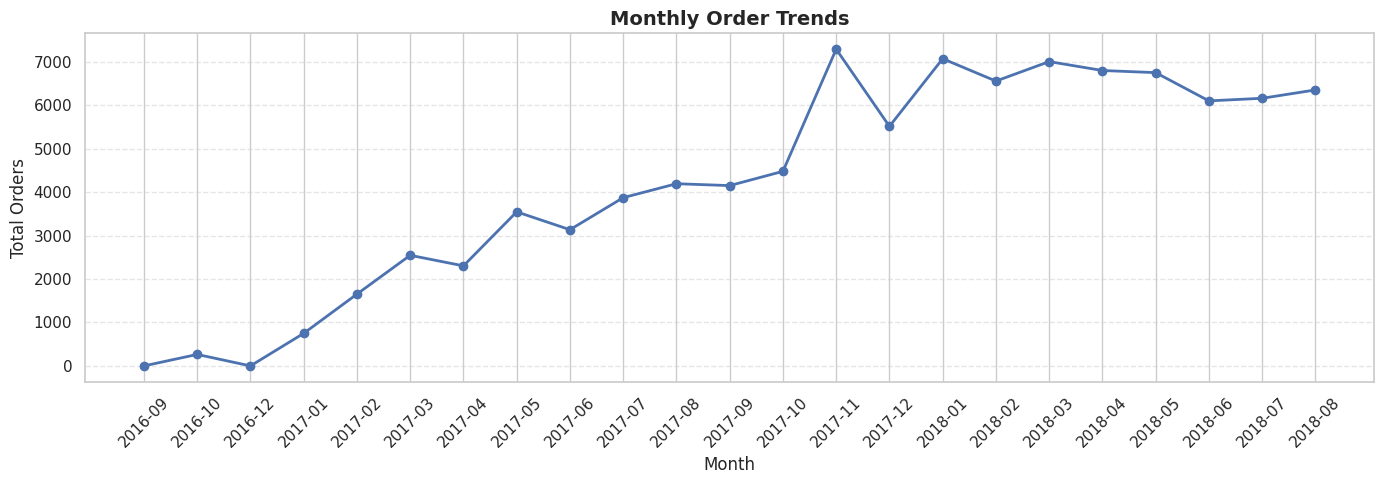

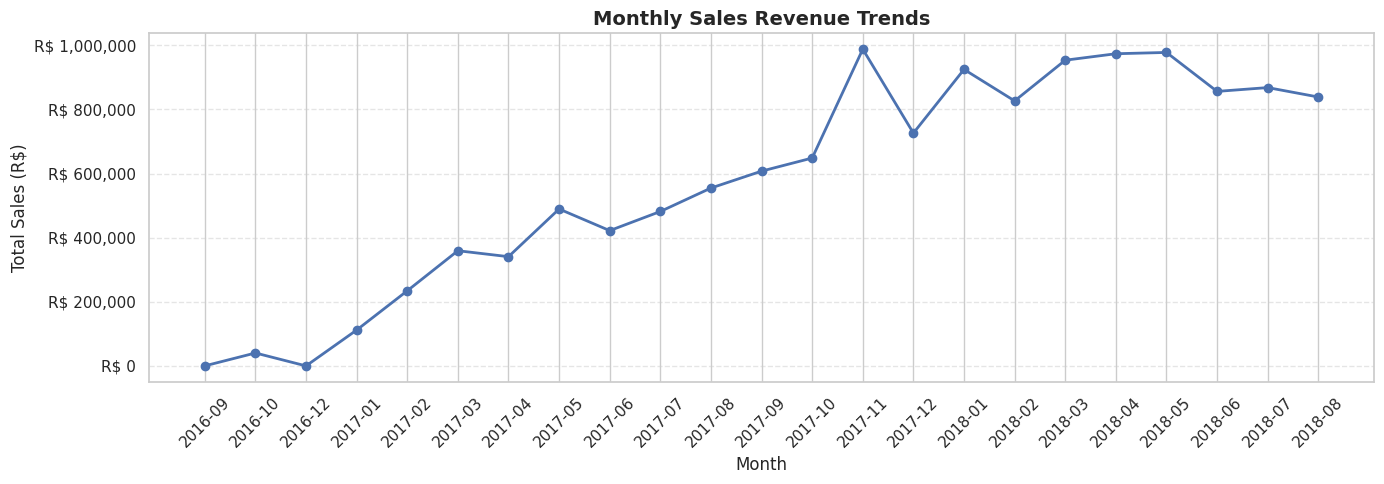

In [27]:

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

#mengurutkan data berdasarkan bulan
monthly_sales = monthly_sales.sort_values('month')

#visualisasi 1: Jumlah Pesanan per Bulan
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales['month'],
    monthly_sales['total_orders'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Order Trends', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Orders')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#visualisasi 2: Total Nilai Penjualan per Bulan
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales['month'],
    monthly_sales['total_sales'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Revenue Trends', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales (R$)')
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('R$ {x:,.0f}')
)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary selama periode pengamatan, serta segmen pelanggan mana yang perlu diprioritaskan dalam strategi retensi?

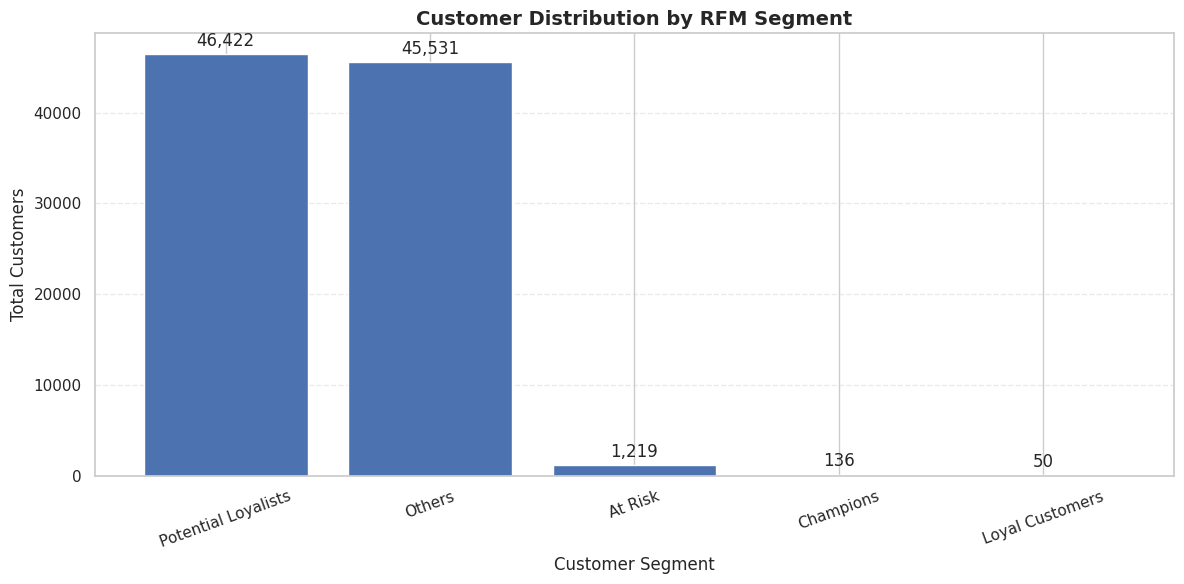

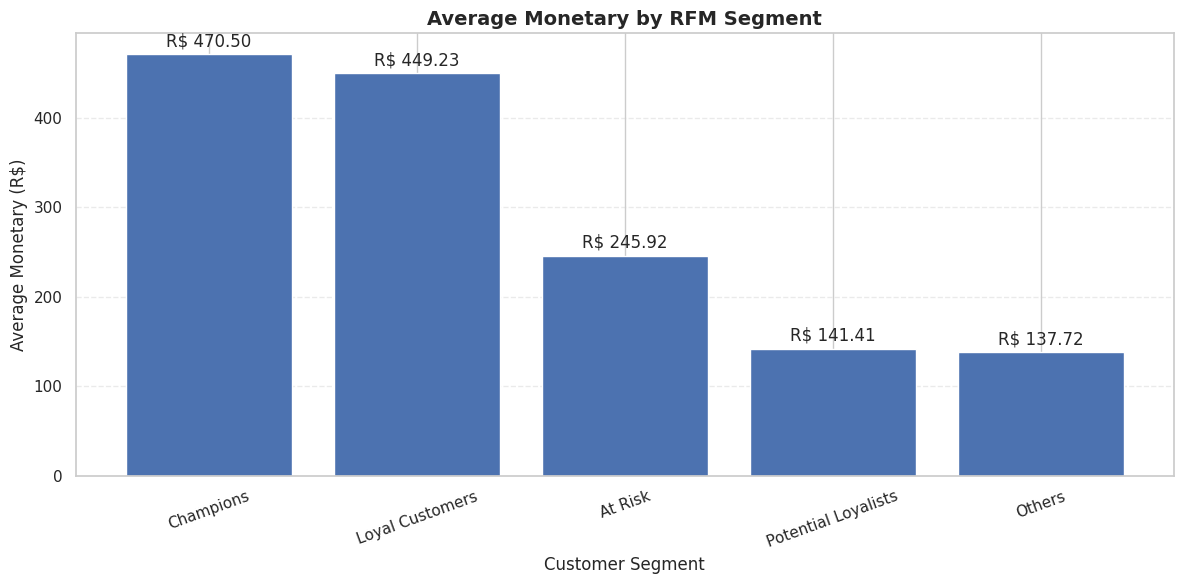

In [28]:
#mengurutkan segmen berdasarkan jumlah pelanggan
rfm_plot = rfm_summary.sort_values(
    'total_customers', ascending=False
)

#visualisasi 1: Distribusi Pelanggan berdasarkan Segmen
plt.figure(figsize=(12, 6))

bars = plt.bar(
    rfm_plot['customer_segment'],
    rfm_plot['total_customers']
)

plt.title(
    'Customer Distribution by RFM Segment',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Customer Segment')
plt.ylabel('Total Customers')
plt.xticks(rotation=20)

plt.bar_label(bars, fmt='{:,.0f}', padding=3)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#visualisasi 2: Rata-rata Monetary berdasarkan Segmen
rfm_monetary = rfm_summary.sort_values(
    'avg_monetary', ascending=False
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    rfm_monetary['customer_segment'],
    rfm_monetary['avg_monetary']
)

plt.title(
    'Average Monetary by RFM Segment',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Customer Segment')
plt.ylabel('Average Monetary (R$)')
plt.xticks(rotation=20)

plt.bar_label(bars, fmt='R$ {:,.2f}', padding=3)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Pertanyaan 3:
Bagaimana persebaran pelanggan berdasarkan negara bagian di Brazil, dan wilayah mana yang memberikan kontribusi jumlah pesanan serta nilai penjualan terbesar selama periode pengamatan?

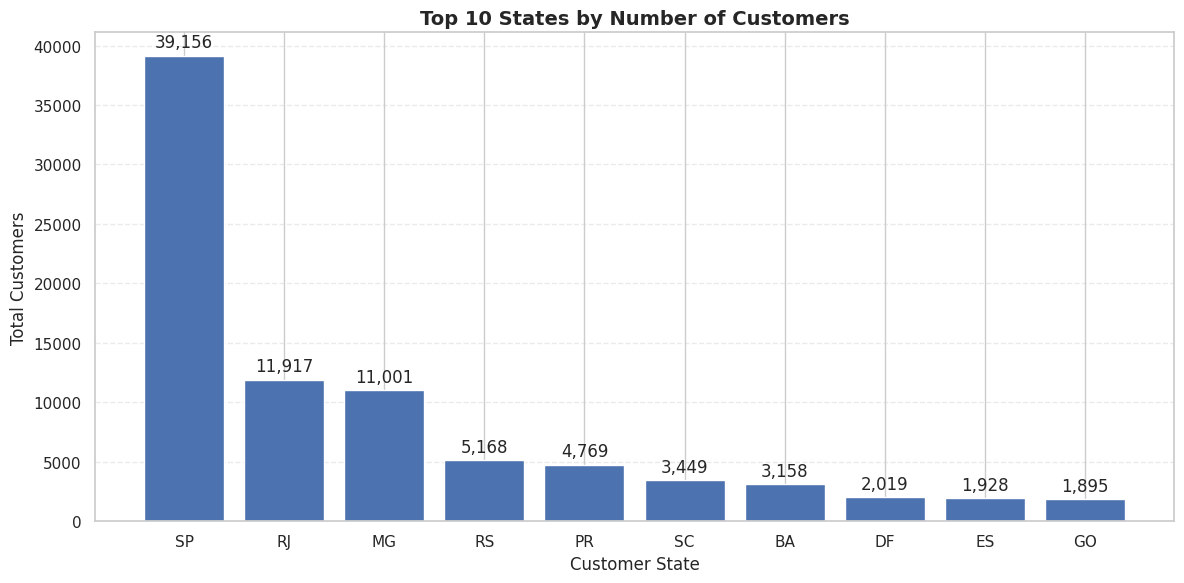

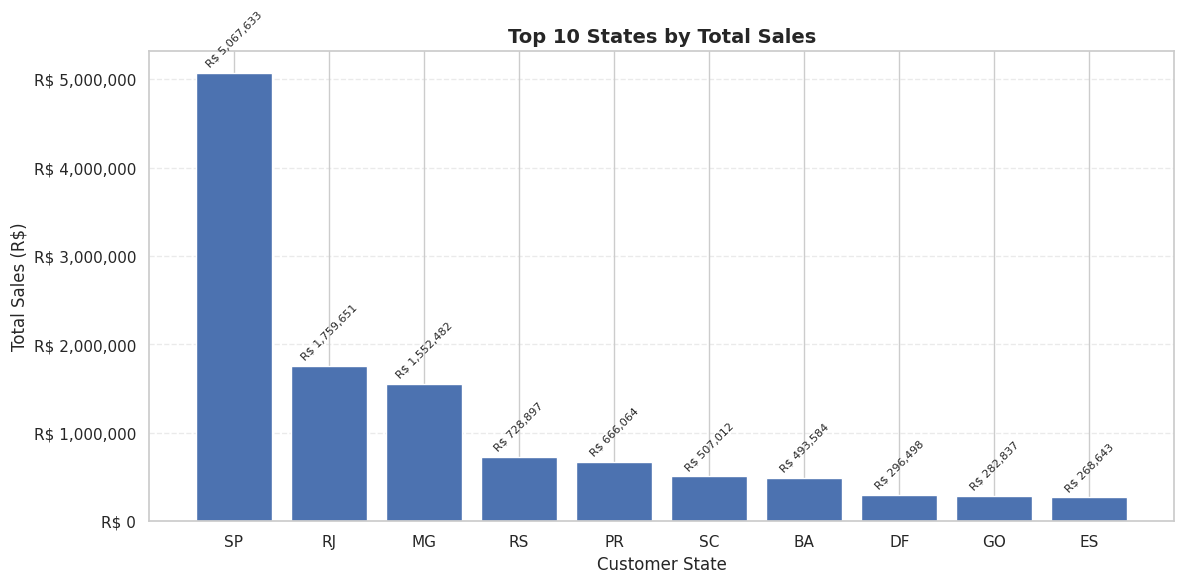

In [29]:
#menggabungkan data pelanggan, pesanan, dan item pesanan
geo_data = (
    delivered_orders[['order_id', 'customer_id']]
    .merge(
        customers_df[['customer_id', 'customer_unique_id', 'customer_state']],
        on='customer_id',
        how='left'
    )
    .merge(
        order_items_df[['order_id', 'price']],
        on='order_id',
        how='left'
    )
)

#menghitung performa setiap negara bagian
geo_summary = geo_data.groupby('customer_state').agg(
    total_customers=('customer_unique_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_sales=('price', 'sum')
).reset_index()

#menghitung persentase kontribusi penjualan
geo_summary['sales_percentage'] = (
    geo_summary['total_sales']
    / geo_summary['total_sales'].sum() * 100
).round(2)

#visualisasi top 10 negara bagian berdasarkan jumlah pelanggan
top_customers = geo_summary.sort_values(
    'total_customers', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    top_customers['customer_state'],
    top_customers['total_customers']
)

plt.title(
    'Top 10 States by Number of Customers',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Customer State')
plt.ylabel('Total Customers')
plt.bar_label(bars, fmt='{:,.0f}', padding=3)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#visualisasi top 10 negara bagian berdasarkan nilai penjualan
top_sales = geo_summary.sort_values(
    'total_sales', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    top_sales['customer_state'],
    top_sales['total_sales']
)

plt.title(
    'Top 10 States by Total Sales',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Customer State')
plt.ylabel('Total Sales (R$)')

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('R$ {x:,.0f}')
)

plt.bar_label(
    bars,
    labels=[
        f'R$ {value:,.0f}'
        for value in top_sales['total_sales']
    ],
    padding=3,
    rotation=45,
    fontsize=8
)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pertanyaan 1 (tren penjualan bulanan): Berdasarkan visualisasi, aktivitas penjualan mengalami peningkatan sepanjang tahun 2017. Jumlah pesanan meningkat dari sekitar 750 pesanan pada Januari 2017 menjadi 7.289 pesanan pada November 2017. Nilai penjualan juga meningkat dari sekitar R111.798 menjadi R987.765,37 pada periode yang sama. November 2017 menjadi bulan dengan performa tertinggi berdasarkan jumlah pesanan dan total nilai penjualan. Sementara itu, sepanjang tahun 2018, jumlah pesanan cenderung stabil pada kisaran 6.100–7.100 pesanan per bulan. Data pada beberapa bulan di akhir 2016 masih relatif sedikit sehingga perlu diperhatikan ketika membandingkan tren antartahun.
- Pertanyaan 2 (segmentasi RFM): Hasil segmentasi menunjukkan bahwa sebagian besar pelanggan termasuk dalam segmen Potential Loyalists, yaitu sebanyak 46.422 pelanggan atau 49,72%. Segmen Others juga memiliki jumlah yang besar, yaitu 45.531 pelanggan atau 48,77%.Rata-rata Frequency pelanggan sebesar 1,03 menunjukkan bahwa sebagian besar pelanggan hanya melakukan satu kali pembelian selama periode pengamatan. Segmen Champions berjumlah 136 pelanggan dengan rata-rata Monetary sebesar R470,50, sedangkan Loyal Customers berjumlah 50 pelanggan dengan rata-rata Monetary sebesar R449,23.Segmen At Risk terdiri dari 1.219 pelanggan dengan rata-rata Recency sekitar 354 hari dan rata-rata Monetary sebesar R$245,92. Kondisi ini menunjukkan perlunya strategi untuk mendorong pembelian ulang dan mempertahankan pelanggan yang berisiko tidak kembali bertransaksi.
- Pertanyaan 3 (persebaran wilayah): Hasil analisis menunjukkan bahwa negara bagian São Paulo (SP) memiliki kontribusi terbesar dengan 39.156 pelanggan dan 40.501 pesanan. Nilai penjualannya mencapai sekitar R5.067.633,16 atau 38,33% dari total penjualan.Rio de Janeiro (RJ) memberikan kontribusi penjualan sebesar 13,31%, sedangkan Minas Gerais (MG) sebesar 11,74%. Ketiga negara bagian tersebut secara keseluruhan menyumbang sekitar 63,4% dari total nilai penjualan. Sebaliknya, beberapa negara bagian di wilayah utara Brazil, seperti Roraima (RR), Amapá (AP), Acre (AC), dan Amazonas (AM), memiliki kontribusi penjualan yang relatif kecil. Hal ini menunjukkan bahwa aktivitas penjualan dalam dataset lebih terkonsentrasi di beberapa negara bagian utama.

## Analisis Lanjutan (Opsional)
(Binning Analysis)

In [30]:
#mengambil ID pesanan yang berstatus delivered
delivered_order_ids = orders_df.loc[
    orders_df['order_status'] == 'delivered', 'order_id'
]

#memfilter data item berdasarkan pesanan delivered
delivered_items = order_items_df[
    order_items_df['order_id'].isin(delivered_order_ids)
].copy()

#menghitung total nilai pembelian setiap pesanan
order_value = delivered_items.groupby('order_id')['price'].sum().reset_index()
order_value.columns = ['order_id', 'order_value']

#membagi nilai pesanan ke dalam empat kelompok
order_value['value_segment'] = pd.qcut(
    order_value['order_value'].rank(method='first'),
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

#membuat ringkasan berdasarkan kelompok nilai pesanan
binning_summary = order_value.groupby(
    'value_segment', observed=False
).agg(
    total_orders=('order_id', 'count'),
    total_sales=('order_value', 'sum'),
    avg_order_value=('order_value', 'mean')
).reset_index()

#menghitung persentase kontribusi penjualan
binning_summary['sales_percentage'] = (
    binning_summary['total_sales'] /
    binning_summary['total_sales'].sum() * 100
)

binning_summary

,value_segment,total_orders,total_sales,avg_order_value,sales_percentage
0,Low,24120,"687,812.97",28.52,5.20
1,Medium,24119,"1,537,209.66",63.73,11.63
2,High,24119,"2,764,192.36",114.61,20.91
3,Very High,24120,"8,232,283.12",341.31,62.26


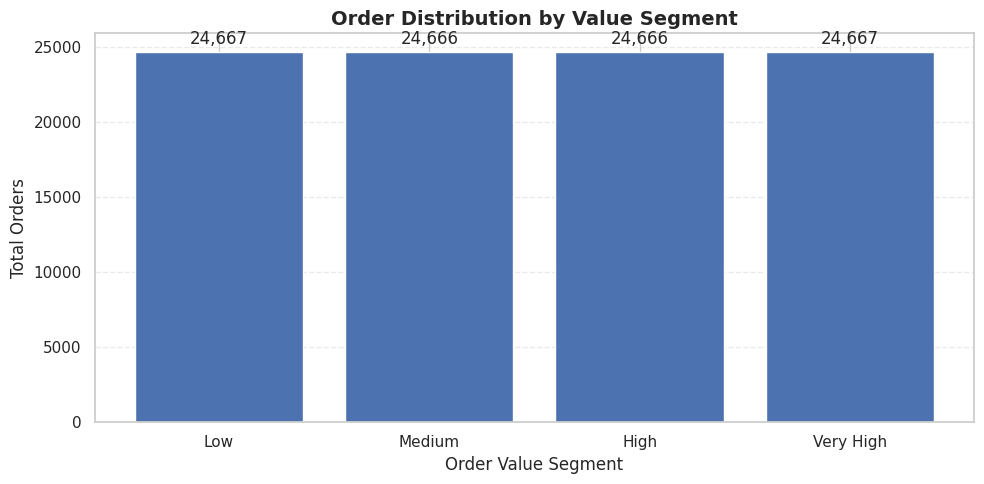

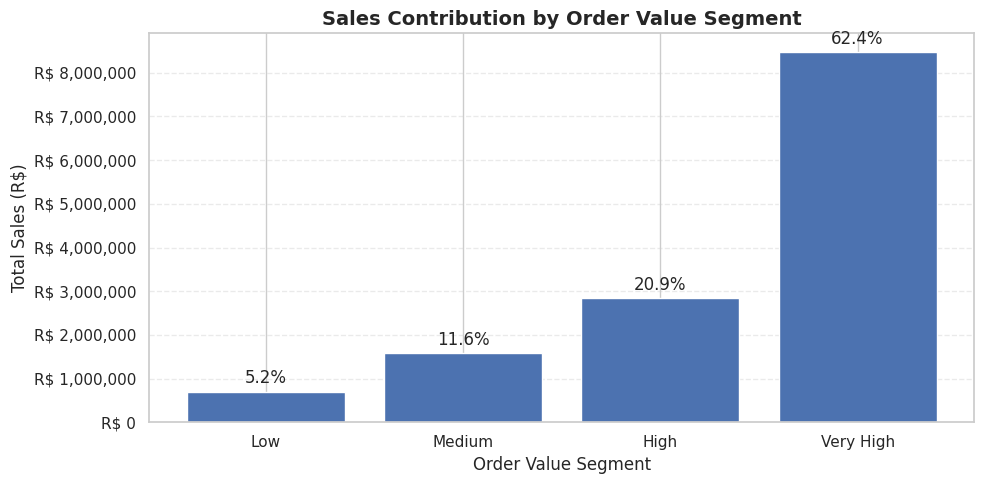

In [31]:
#visualisasi 1: Distribusi Jumlah Pesanan
plt.figure(figsize=(10, 5))

bars = plt.bar(
    order_segment_summary['order_segment'].astype(str),
    order_segment_summary['total_orders']
)

plt.title(
    'Order Distribution by Value Segment',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Order Value Segment')
plt.ylabel('Total Orders')
plt.bar_label(bars, fmt='{:,.0f}', padding=3)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#visualisasi 2: Kontribusi Penjualan
plt.figure(figsize=(10, 5))

bars = plt.bar(
    order_segment_summary['order_segment'].astype(str),
    order_segment_summary['total_sales']
)

plt.title(
    'Sales Contribution by Order Value Segment',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Order Value Segment')
plt.ylabel('Total Sales (R$)')

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('R$ {x:,.0f}')
)

plt.bar_label(
    bars,
    labels=[
        f'{value:.1f}%'
        for value in order_segment_summary['sales_percentage']
    ],
    padding=3
)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pesanan terbagi ke empat kelompok berdasarkan nilai pesanan dengan jumlah yang hampir sama (sekitar 24.666-24.667 pesanan per kelompok), tetapi kontribusi penjualannya sangat timpang.
- Kelompok Very High (25% pesanan dengan nilai tertinggi) menyumbang 62,39% total penjualan (R 8,48juta)denganrata−ratanilaipesananR  343,78. Kelompok High menyumbang 20,85% (rata-rata R 114,88).
- Kelompok Low dan Medium secara gabungan hanya menyumbang sekitar 16,76 ; 28,53 dan R$63,83. Artinya, pesanan bernilai kecil jumlahnya banyak tetapi dampak pendapatannya relatif kecil.
- Analisis ini menggunakan nilai produk (price) tanpa ongkos kirim dan mencakup seluruh status pesanan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Jumlah pesanan dan nilai penjualan meningkat sepanjang tahun 2017 dan mencapai puncaknya pada November 2017, dengan 7.289 pesanan dan total nilai penjualan sebesar R 987.765,37. Sepanjang tahun 2018, performa penjualan cenderung stabil pada kisaran 6.100–7.100 pesanan per bulan, tetapi tidak melampaui puncak November 2017.
- **Conclusion pertanyaan 2:** Mayoritas pelanggan termasuk dalam segmen Potential Loyalists (46.422 pelanggan atau 49,72%), diikuti segmen Others (45.531 pelanggan atau 48,77%). Rata-rata Frequency sebesar 1,03 menunjukkan bahwa sebagian besar pelanggan hanya melakukan satu kali pembelian selama periode pengamatan. Potential Loyalists dapat diprioritaskan untuk mendorong pembelian kedua, sedangkan At Risk dapat menjadi sasaran strategi reaktivasi karena rata-rata Recency-nya sekitar 354 hari.
- **Conclusion Pertanyaan 3:**  São Paulo merupakan negara bagian dengan jumlah pelanggan (39.156), jumlah pesanan (40.501), dan nilai penjualan terbesar (sekitar R$5,07 juta atau 38,33%). Bersama Rio de Janeiro dan Minas Gerais, ketiga negara bagian tersebut menyumbang sekitar 63,4% dari total penjualan.
- **Analisis Lanjutan (binning):** Kelompok Very High mencakup sekitar 25% pesanan dengan nilai tertinggi dan menyumbang 62,26% dari total nilai penjualan. Hal ini menunjukkan bahwa kelompok pesanan bernilai tinggi memberikan kontribusi besar terhadap total penjualan.

**Rekomendasi Action Item:**
- Retensi pelanggan baru (Potential Loyalists): Berikan voucher atau penawaran pembelian kedua dalam waktu singkat setelah transaksi pertama, mengingat hampir seluruh pelanggan hanya membeli satu kali.
- Reaktivasi segmen At Risk dan Others: Jalankan kampanye win-back (email atau notifikasi dengan promo personal), dimulai dari At Risk karena nilai belanja rata-ratanya lebih tinggi.
- Pertahankan pelanggan bernilai tinggi: Buat program loyalitas atau layanan prioritas bagi Champions dan Loyal Customers, serta dorong pelanggan segmen lain naik ke level ini.
- Manfaatkan momentum musiman: Siapkan stok, logistik, dan anggaran promosi lebih awal untuk periode puncak seperti November, karena November 2017 menjadi bulan dengan performa tertinggi.
- Fokus wilayah: Pertahankan layanan dan logistik di São Paulo, Rio de Janeiro, dan Minas Gerais sebagai penyumbang utama, sambil menguji kampanye atau promo ongkos kirim di wilayah dengan kontribusi rendah untuk melihat potensi pertumbuhannya.
- Dorong nilai pesanan: Terapkan bundling, rekomendasi produk pelengkap, atau minimum belanja untuk gratis ongkir agar pesanan kelompok Low dan Medium naik ke nilai yang lebih tinggi.